In [1]:
# EV Battery Health & Range Estimation Using AI
# Step 1: Set up the project environment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Project setup successful!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("All basic libraries are ready.")

Project setup successful!
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
All basic libraries are ready.


In [2]:
import urllib.request
import zipfile
import os

url = "https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip"
zip_path = "/content/battery.zip"
extract_path = "/content/battery_data"

print("Downloading dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Download complete!")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete!")

for root, dirs, files in os.walk(extract_path):
    for name in files[:10]:
        print(os.path.join(root, name))

Download complete!
Extraction complete!
/content/battery_data/5. Battery Data Set/2. BatteryAgingARC_25_26_27_28_P1.zip
/content/battery_data/5. Battery Data Set/5. BatteryAgingARC_49_50_51_52.zip
/content/battery_data/5. Battery Data Set/3. BatteryAgingARC_25-44.zip
/content/battery_data/5. Battery Data Set/1. BatteryAgingARC-FY08Q4.zip
/content/battery_data/5. Battery Data Set/6. BatteryAgingARC_53_54_55_56.zip
/content/battery_data/5. Battery Data Set/4. BatteryAgingARC_45_46_47_48.zip


In [3]:
import zipfile
import os

base_path = "/content/battery_data/5. Battery Data Set"

for filename in os.listdir(base_path):
    if filename.endswith(".zip"):
        zip_path = os.path.join(base_path, filename)
        extract_folder = os.path.join(
            base_path, filename.replace(".zip", "")
        )

        os.makedirs(extract_folder, exist_ok=True)

        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(extract_folder)

        print("Extracted:", filename)

print("\nAll inner ZIP files extracted!")

Extracted: 2. BatteryAgingARC_25_26_27_28_P1.zip
Extracted: 5. BatteryAgingARC_49_50_51_52.zip
Extracted: 3. BatteryAgingARC_25-44.zip
Extracted: 1. BatteryAgingARC-FY08Q4.zip
Extracted: 6. BatteryAgingARC_53_54_55_56.zip
Extracted: 4. BatteryAgingARC_45_46_47_48.zip

All inner ZIP files extracted!


In [4]:
import os

base_path = "/content/battery_data"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith((".mat", ".csv", ".txt", ".xlsx")):
            print(os.path.join(root, file))

/content/battery_data/5. Battery Data Set/5. BatteryAgingARC_49_50_51_52/B0049.mat
/content/battery_data/5. Battery Data Set/5. BatteryAgingARC_49_50_51_52/README_49_50_51_52.txt
/content/battery_data/5. Battery Data Set/5. BatteryAgingARC_49_50_51_52/B0051.mat
/content/battery_data/5. Battery Data Set/5. BatteryAgingARC_49_50_51_52/B0052.mat
/content/battery_data/5. Battery Data Set/5. BatteryAgingARC_49_50_51_52/B0050.mat
/content/battery_data/5. Battery Data Set/6. BatteryAgingARC_53_54_55_56/B0054.mat
/content/battery_data/5. Battery Data Set/6. BatteryAgingARC_53_54_55_56/README_53_54_55_56.txt
/content/battery_data/5. Battery Data Set/6. BatteryAgingARC_53_54_55_56/B0056.mat
/content/battery_data/5. Battery Data Set/6. BatteryAgingARC_53_54_55_56/B0055.mat
/content/battery_data/5. Battery Data Set/6. BatteryAgingARC_53_54_55_56/B0053.mat
/content/battery_data/5. Battery Data Set/2. BatteryAgingARC_25_26_27_28_P1/B0027.mat
/content/battery_data/5. Battery Data Set/2. BatteryAgingA

In [5]:

from scipy.io import loadmat
import os

file_path = "/content/battery_data/5. Battery Data Set/1. BatteryAgingARC-FY08Q4/B0005.mat"

data = loadmat(file_path)

print("Dataset loaded successfully!")
print("Available keys:")
print(data.keys())


Dataset loaded successfully!
Available keys:
dict_keys(['__header__', '__version__', '__globals__', 'B0005'])


In [7]:
battery = data["B0005"]

print("Battery data type:", type(battery))
print("Battery data shape:", battery.shape)
print("Battery structure:")
print(battery.dtype)


Battery data type: <class 'numpy.ndarray'>
Battery data shape: (1, 1)
Battery structure:
[('cycle', 'O')]


In [8]:

# Step 3 + Step 4: Access and inspect battery cycle data

from scipy.io import loadmat

file_path = "/content/battery_data/5. Battery Data Set/1. BatteryAgingARC-FY08Q4/B0005.mat"

# Load dataset
data = loadmat(file_path)

# Access battery cycle data
cycle_data = data["B0005"]["cycle"][0, 0]

# Display dataset information
print("Dataset loaded successfully!")
print("Cycle data type:", type(cycle_data))
print("Cycle data shape:", cycle_data.shape)
print("Cycle data fields:", cycle_data.dtype.names)

# Display number of cycles
print("\nNumber of cycles:", len(cycle_data))

# Display first cycle details
print("\nFirst cycle details:")
print(cycle_data[0])


Streaming output truncated to the last 5000 lines.
                [0.08608558-8.70127581e-04j],
                [0.08387182-1.10259892e-03j],
                [0.08522679-1.33754474e-03j],
                [0.08483048-7.35959224e-04j],
                [0.08251976-5.00290650e-04j],
                [0.08406517-8.89489990e-04j],
                [0.08333045-1.09439192e-03j],
                [0.08143529-1.97743408e-03j],
                [0.08346878-1.84847170e-03j],
                [0.08261372-2.37669756e-03j],
                [0.08092532-1.91694388e-03j],
                [0.08011934-2.03055074e-03j],
                [0.07951886-1.92721630e-03j],
                [0.07928976-1.52107800e-03j],
                [0.0770073 -1.74788773e-03j],
                [0.07452183-2.43702152e-03j],
                [0.07429914-1.87947961e-03j],
                [0.07307397-2.01757732e-03j],
                [0.07218413-2.34060771e-03j],
                [0.06782252-2.69538376e-03j],
                [0.06838406-1

Battery capacity summary:
 Cycle  Capacity_Ah
     2     1.856487
     4     1.846327
     6     1.835349
     8     1.835263
    10     1.834646
    12     1.835662
    14     1.835146
    16     1.825757
    18     1.824774
    20     1.824613

Total discharge cycles: 168


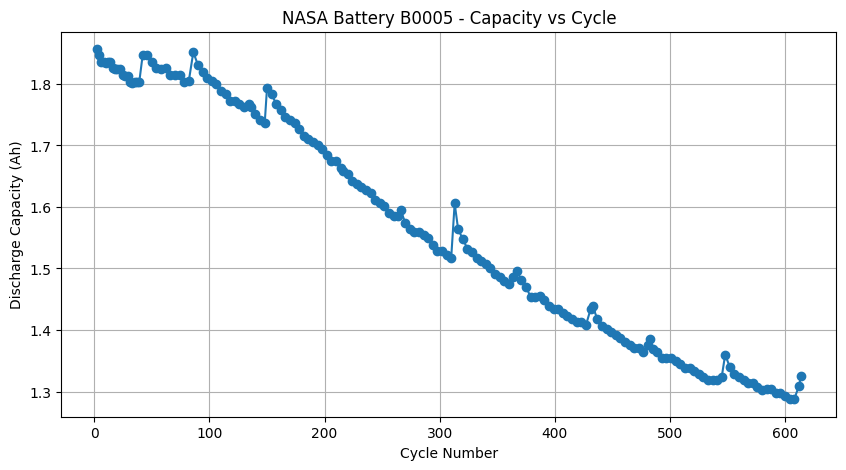

In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load battery data
battery = data["B0005"][0, 0]
cycles = battery["cycle"][0]

# Extract discharge-cycle capacity
cycle_numbers = []
capacities = []

for i, cycle in enumerate(cycles):
    cycle_type = cycle["type"][0]

    if cycle_type == "discharge":
        capacity = cycle["data"][0, 0]["Capacity"][0, 0]

        cycle_numbers.append(i + 1)
        capacities.append(float(capacity))

# Display first 10 rows
df = pd.DataFrame({
    "Cycle": cycle_numbers,
    "Capacity_Ah": capacities
})

print("Battery capacity summary:")
print(df.head(10).to_string(index=False))
print("\nTotal discharge cycles:", len(df))

# Plot graph
plt.figure(figsize=(10, 5))
plt.plot(df["Cycle"], df["Capacity_Ah"], marker="o")
plt.title("NASA Battery B0005 - Capacity vs Cycle")
plt.xlabel("Cycle Number")
plt.ylabel("Discharge Capacity (Ah)")
plt.grid(True)
plt.show()


In [10]:
from sklearn.model_selection import train_test_split

# Input feature: cycle number
X = df[["Cycle"]]

# Target: battery discharge capacity
y = df["Capacity_Ah"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Dataset preparation completed!")

Training samples: 134
Testing samples: 34
Dataset preparation completed!


STEP 1-2: Dataset loaded successfully!

First 10 discharge cycles:
 Cycle  Capacity_Ah
     1     1.856487
     2     1.846327
     3     1.835349
     4     1.835263
     5     1.834646
     6     1.835662
     7     1.835146
     8     1.825757
     9     1.824774
    10     1.824613

Total discharge cycles: 168


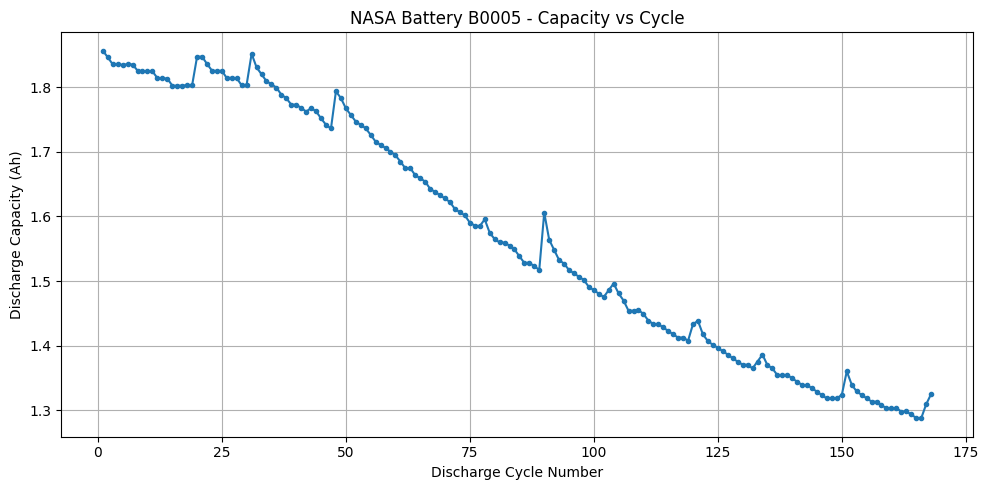


STEP 3: Data preparation completed!
Training samples: 134
Testing samples: 34

STEP 4: Model training completed!

MODEL EVALUATION
----------------
Mean Absolute Error (MAE): 0.0309 Ah
Root Mean Squared Error (RMSE): 0.0388 Ah
R² Score: -2.0554

Actual vs Predicted (first 10 test samples):
 Cycle  Actual_Capacity_Ah  Predicted_Capacity_Ah
   135              1.3699                 1.3611
   136              1.3648                 1.3571
   137              1.3543                 1.3530
   138              1.3546                 1.3489
   139              1.3547                 1.3449
   140              1.3493                 1.3408
   141              1.3442                 1.3368
   142              1.3390                 1.3327
   143              1.3389                 1.3286
   144              1.3340                 1.3246


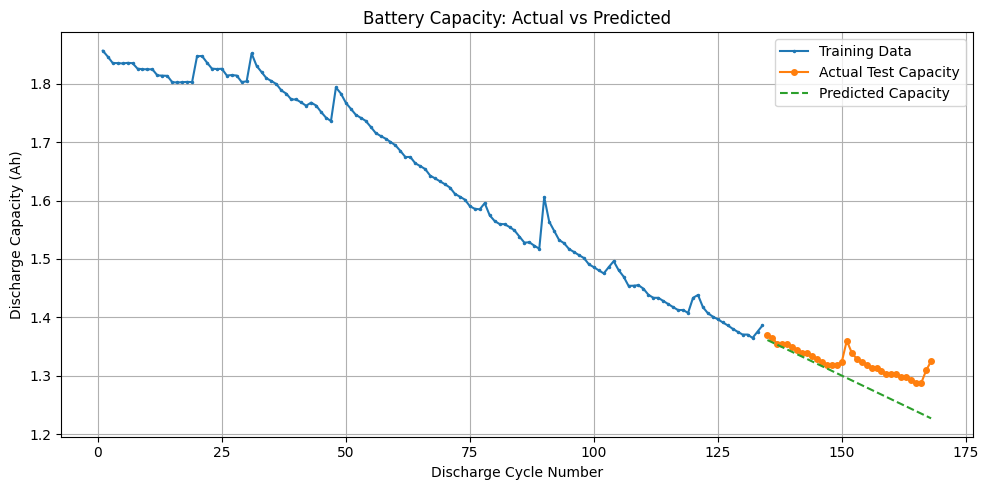


Enter a future discharge cycle number to predict capacity: 170
Predicted capacity at cycle 170: 1.2190 Ah
Note: This is an extrapolation beyond the observed data; accuracy is not guaranteed.

PROJECT PIPELINE COMPLETED!
Saved files:
/content/battery_capacity_graph.png
/content/battery_prediction_graph.png
/content/battery_capacity_data.csv
/content/battery_prediction_results.csv


In [13]:

# PROJECT: Battery Health Prediction Using Machine Learning
# Dataset: NASA Battery Aging Dataset - Battery B0005

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# STEP 1: Load the NASA battery dataset
file_path = "/content/battery_data/5. Battery Data Set/1. BatteryAgingARC-FY08Q4/B0005.mat"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Dataset file not found: {file_path}\n"
        "Check the file path in your Colab environment."
    )

data = loadmat(file_path)
battery = data["B0005"][0, 0]
cycles = battery["cycle"][0]

# STEP 2: Extract discharge capacity
cycle_numbers = []
capacities = []
discharge_count = 0

for i, cycle in enumerate(cycles):
    cycle_type = "".join(
        np.asarray(cycle["type"]).astype(str).flatten()
    ).strip()

    if cycle_type.lower() == "discharge":
        record = cycle["data"][0, 0]
        capacity = float(np.asarray(record["Capacity"]).flatten()[0])

        if np.isfinite(capacity):
            discharge_count += 1
            cycle_numbers.append(discharge_count)
            capacities.append(capacity)

# Create the dataset
df = pd.DataFrame({
    "Cycle": cycle_numbers,
    "Capacity_Ah": capacities
})

if len(df) < 5:
    raise ValueError(
        "Too few discharge cycles were extracted. "
        "Check the dataset structure."
    )

print("STEP 1-2: Dataset loaded successfully!")
print("\nFirst 10 discharge cycles:")
print(df.head(10).to_string(index=False))
print("\nTotal discharge cycles:", len(df))

# STEP 3: Plot capacity degradation
plt.figure(figsize=(10, 5))
plt.plot(df["Cycle"], df["Capacity_Ah"], marker="o", markersize=3)
plt.title("NASA Battery B0005 - Capacity vs Cycle")
plt.xlabel("Discharge Cycle Number")
plt.ylabel("Discharge Capacity (Ah)")
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/battery_capacity_graph.png", dpi=300)
plt.show()

# STEP 4: Prepare training and testing data
X = df[["Cycle"]]
y = df["Capacity_Ah"]

# Keep later cycles for testing to respect time order
split_index = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("\nSTEP 3: Data preparation completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# STEP 5: Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nSTEP 4: Model training completed!")

# STEP 6: Predict test capacities and evaluate
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nMODEL EVALUATION")
print("----------------")
print(f"Mean Absolute Error (MAE): {mae:.4f} Ah")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} Ah")
print(f"R² Score: {r2:.4f}")

# Compare actual and predicted capacities
results = pd.DataFrame({
    "Cycle": X_test["Cycle"].values,
    "Actual_Capacity_Ah": y_test.values,
    "Predicted_Capacity_Ah": y_pred
})

print("\nActual vs Predicted (first 10 test samples):")
print(results.head(10).round(4).to_string(index=False))

# STEP 7: Plot actual vs predicted capacity
plt.figure(figsize=(10, 5))
plt.plot(
    X_train["Cycle"], y_train,
    label="Training Data", marker=".", markersize=3
)
plt.plot(
    X_test["Cycle"], y_test,
    label="Actual Test Capacity", marker="o", markersize=4
)
plt.plot(
    X_test["Cycle"], y_pred,
    label="Predicted Capacity", linestyle="--"
)
plt.title("Battery Capacity: Actual vs Predicted")
plt.xlabel("Discharge Cycle Number")
plt.ylabel("Discharge Capacity (Ah)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/battery_prediction_graph.png", dpi=300)
plt.show()

# STEP 8: Predict capacity for a user-selected future cycle
future_cycle = int(input(
    "\nEnter a future discharge cycle number to predict capacity: "
))

if future_cycle <= 0:
    print("Please enter a positive cycle number.")
else:
    future_capacity = model.predict(
        pd.DataFrame({"Cycle": [future_cycle]})
    )[0]

    print(
        f"Predicted capacity at cycle {future_cycle}: "
        f"{future_capacity:.4f} Ah"
    )

    if future_cycle > df["Cycle"].max():
        print(
            "Note: This is an extrapolation beyond the observed data; "
            "accuracy is not guaranteed."
        )

# STEP 9: Save extracted data and predictions
df.to_csv("/content/battery_capacity_data.csv", index=False)
results.to_csv("/content/battery_prediction_results.csv", index=False)

print("\nPROJECT PIPELINE COMPLETED!")
print("Saved files:")
print("/content/battery_capacity_graph.png")
print("/content/battery_prediction_graph.png")
print("/content/battery_capacity_data.csv")
print("/content/battery_prediction_results.csv")


Dataset found: /content/battery_data/5. Battery Data Set/1. BatteryAgingARC-FY08Q4/B0005.mat

STEP 1: DATASET LOADED
Total discharge cycles: 168

First 10 records:
 Cycle  Capacity_Ah
     1       1.8565
     2       1.8463
     3       1.8353
     4       1.8353
     5       1.8346
     6       1.8357
     7       1.8351
     8       1.8258
     9       1.8248
    10       1.8246

STEP 2: BATTERY HEALTH
Initial capacity: 1.8565 Ah
Final capacity: 1.3251 Ah
Final recorded SOH: 71.38 %


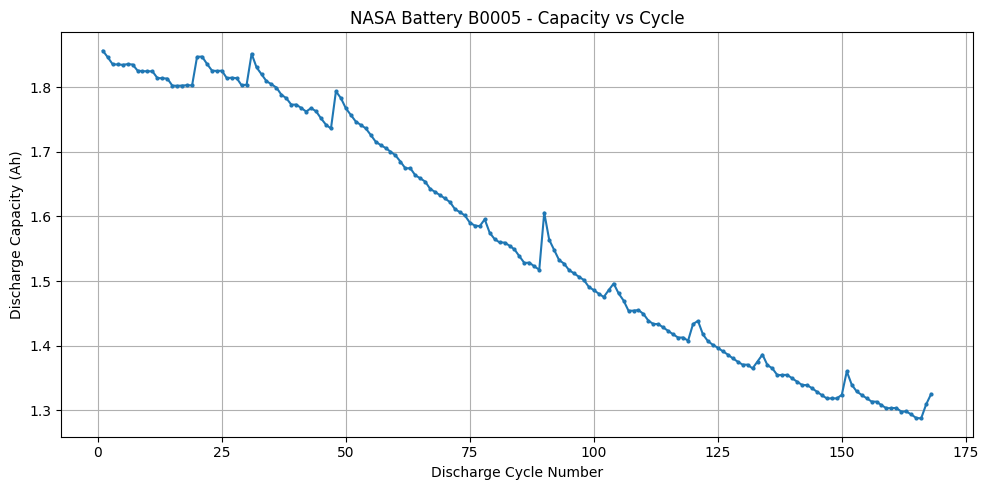

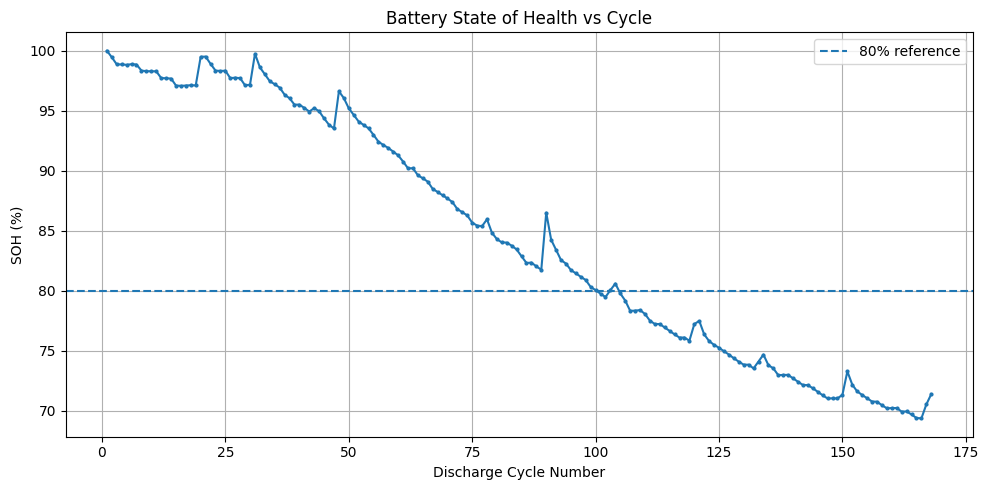


STEP 3: DATA PREPARATION
Training samples: 134
Testing samples: 34

STEP 4: MODEL EVALUATION
MAE: 0.0309 Ah
RMSE: 0.0388 Ah
R2 Score: -2.0554

Actual vs Predicted:
 Cycle  Actual_Capacity_Ah  Predicted_Capacity_Ah
   135              1.3699                 1.3611
   136              1.3648                 1.3571
   137              1.3543                 1.3530
   138              1.3546                 1.3489
   139              1.3547                 1.3449
   140              1.3493                 1.3408
   141              1.3442                 1.3368
   142              1.3390                 1.3327
   143              1.3389                 1.3286
   144              1.3340                 1.3246


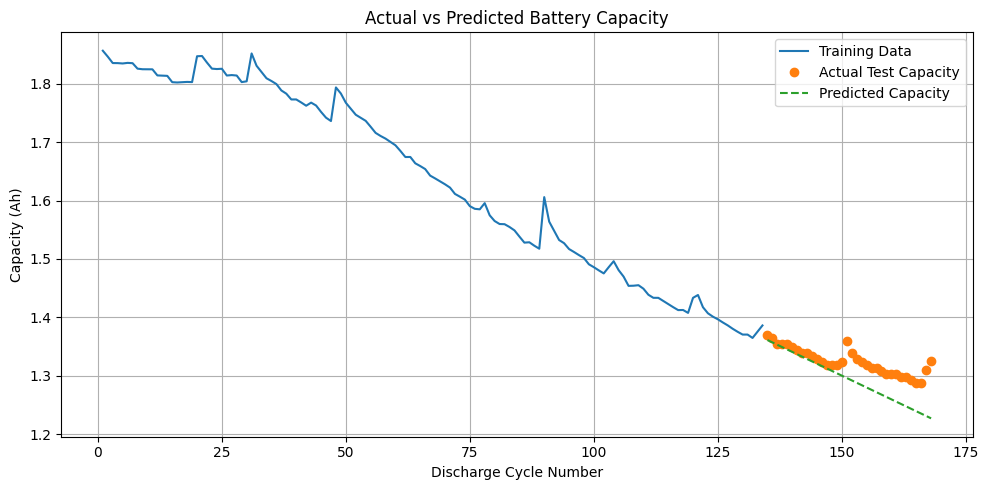


Enter a future discharge cycle number to predict capacity: 168
Predicted capacity at cycle 168: 1.2271 Ah

FINAL PROJECT RESULTS
Project: Battery Health Prediction Using Machine Learning
Dataset: NASA Battery B0005
Discharge cycles analysed: 168
Initial capacity: 1.8565 Ah
Final capacity: 1.3251 Ah
Capacity loss: 28.62 %
Final recorded SOH: 71.38 %
MAE: 0.0309 Ah
RMSE: 0.0388 Ah
R2 Score: -2.0554

PROJECT COMPLETED!
Saved files:
/content/battery_capacity_graph.png
/content/battery_soh_graph.png
/content/battery_prediction_graph.png
/content/battery_health_dataset.csv
/content/battery_prediction_results.csv

PROJECT CONCLUSION:
The model analyses battery capacity degradation and estimates discharge capacity from cycle number. Model accuracy should be judged using the reported test metrics.


In [17]:

# ============================================================
# BATTERY HEALTH PREDICTION USING MACHINE LEARNING
# NASA Battery Aging Dataset - B0005
# Corrected complete code with automatic file search
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import loadmat
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# STEP 1: FIND B0005.mat AUTOMATICALLY
search_locations = ["/content", os.getcwd()]
file_path = None

for folder in search_locations:
    matches = glob.glob(
        os.path.join(folder, "**", "B0005.mat"),
        recursive=True
    )
    if matches:
        file_path = matches[0]
        break

if file_path is None:
    raise FileNotFoundError(
        "B0005.mat was not found.\n"
        "Upload or extract the NASA battery dataset in Colab, "
        "then run this cell again."
    )

print("Dataset found:", file_path)

# STEP 2: LOAD DATA
data = loadmat(file_path)
battery = data["B0005"][0, 0]
cycles = battery["cycle"][0]

cycle_numbers = []
capacities = []

for cycle in cycles:
    cycle_type = "".join(
        np.asarray(cycle["type"]).astype(str).flatten()
    ).strip().lower()

    if cycle_type == "discharge":
        record = cycle["data"][0, 0]
        values = np.asarray(record["Capacity"]).flatten()

        if values.size:
            capacity = float(values[0])
            if np.isfinite(capacity) and capacity > 0:
                cycle_numbers.append(len(capacities) + 1)
                capacities.append(capacity)

df = pd.DataFrame({
    "Cycle": cycle_numbers,
    "Capacity_Ah": capacities
})

if len(df) < 5:
    raise ValueError(
        "Not enough discharge cycles were extracted. "
        "Check the dataset structure."
    )

print("\nSTEP 1: DATASET LOADED")
print("Total discharge cycles:", len(df))
print("\nFirst 10 records:")
print(df.head(10).round(4).to_string(index=False))

# STEP 3: CALCULATE STATE OF HEALTH (SOH)
initial_capacity = df["Capacity_Ah"].iloc[0]

df["SOH_Percent"] = (
    df["Capacity_Ah"] / initial_capacity
) * 100

print("\nSTEP 2: BATTERY HEALTH")
print("Initial capacity:", round(initial_capacity, 4), "Ah")
print("Final capacity:", round(df["Capacity_Ah"].iloc[-1], 4), "Ah")
print("Final recorded SOH:", round(df["SOH_Percent"].iloc[-1], 2), "%")

# STEP 4: CAPACITY GRAPH
plt.figure(figsize=(10, 5))
plt.plot(df["Cycle"], df["Capacity_Ah"], marker=".", markersize=4)
plt.title("NASA Battery B0005 - Capacity vs Cycle")
plt.xlabel("Discharge Cycle Number")
plt.ylabel("Discharge Capacity (Ah)")
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/battery_capacity_graph.png", dpi=300)
plt.show()

# STEP 5: SOH GRAPH
plt.figure(figsize=(10, 5))
plt.plot(df["Cycle"], df["SOH_Percent"], marker=".", markersize=4)
plt.axhline(80, linestyle="--", label="80% reference")
plt.title("Battery State of Health vs Cycle")
plt.xlabel("Discharge Cycle Number")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/battery_soh_graph.png", dpi=300)
plt.show()

# STEP 6: TRAIN AND TEST DATA
X = df[["Cycle"]]
y = df["Capacity_Ah"]

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("\nSTEP 3: DATA PREPARATION")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# STEP 7: TRAIN MODEL
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# STEP 8: EVALUATE MODEL
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

results = pd.DataFrame({
    "Cycle": X_test["Cycle"].values,
    "Actual_Capacity_Ah": y_test.values,
    "Predicted_Capacity_Ah": y_pred
})

print("\nSTEP 4: MODEL EVALUATION")
print("MAE:", round(mae, 4), "Ah")
print("RMSE:", round(rmse, 4), "Ah")
print("R2 Score:", round(r2, 4))

print("\nActual vs Predicted:")
print(results.head(10).round(4).to_string(index=False))

# STEP 9: PREDICTION GRAPH
plt.figure(figsize=(10, 5))
plt.plot(X_train["Cycle"], y_train, label="Training Data")
plt.plot(X_test["Cycle"], y_test, "o", label="Actual Test Capacity")
plt.plot(X_test["Cycle"], y_pred, "--", label="Predicted Capacity")
plt.title("Actual vs Predicted Battery Capacity")
plt.xlabel("Discharge Cycle Number")
plt.ylabel("Capacity (Ah)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/battery_prediction_graph.png", dpi=300)
plt.show()

# STEP 10: FUTURE CAPACITY PREDICTION
future_cycle = int(input(
    "\nEnter a future discharge cycle number to predict capacity: "
))

if future_cycle <= 0:
    print("Please enter a positive cycle number.")
else:
    predicted_capacity = model.predict(
        pd.DataFrame({"Cycle": [future_cycle]})
    )[0]

    print(
        f"Predicted capacity at cycle {future_cycle}: "
        f"{predicted_capacity:.4f} Ah"
    )

    if future_cycle > df["Cycle"].max():
        print("Note: This is an extrapolation; accuracy is not guaranteed.")

# STEP 11: FINAL RESULTS
capacity_loss = (
    (df["Capacity_Ah"].iloc[0] - df["Capacity_Ah"].iloc[-1])
    / df["Capacity_Ah"].iloc[0]
) * 100

print("\n" + "=" * 50)
print("FINAL PROJECT RESULTS")
print("=" * 50)
print("Project: Battery Health Prediction Using Machine Learning")
print("Dataset: NASA Battery B0005")
print("Discharge cycles analysed:", len(df))
print("Initial capacity:", round(df["Capacity_Ah"].iloc[0], 4), "Ah")
print("Final capacity:", round(df["Capacity_Ah"].iloc[-1], 4), "Ah")
print("Capacity loss:", round(capacity_loss, 2), "%")
print("Final recorded SOH:", round(df["SOH_Percent"].iloc[-1], 2), "%")
print("MAE:", round(mae, 4), "Ah")
print("RMSE:", round(rmse, 4), "Ah")
print("R2 Score:", round(r2, 4))

# STEP 12: SAVE FILES
df.to_csv("/content/battery_health_dataset.csv", index=False)
results.to_csv("/content/battery_prediction_results.csv", index=False)

print("\nPROJECT COMPLETED!")
print("Saved files:")
print("/content/battery_capacity_graph.png")
print("/content/battery_soh_graph.png")
print("/content/battery_prediction_graph.png")
print("/content/battery_health_dataset.csv")
print("/content/battery_prediction_results.csv")

print("\nPROJECT CONCLUSION:")
print(
    "The model analyses battery capacity degradation and estimates "
    "discharge capacity from cycle number. Model accuracy should be "
    "judged using the reported test metrics."
)
